# Q5 — Real-Time Pose Estimation (Webcam Simulation)

**Task:** Detect human pose in real-time from a webcam feed.

Steps:
1. Access webcam using OpenCV (simulated with saved images)
2. Apply pose estimation frame by frame using **YOLOv8n-Pose**
3. Draw skeletons (17 COCO keypoints + connections) and update in real-time
4. Show joint angles (elbow angle, knee angle, shoulder angle)

## Why YOLOv8n-Pose?

MediaPipe 0.10.x removed the classic `mp.solutions.pose` API and
now requires downloading a `.task` model file from Google Storage —
blocked in this cloud environment. YOLOv8n-Pose is the ideal
alternative: it is **faster**, **more accurate**, runs entirely via
GitHub releases (accessible here), and natively outputs the same
17 COCO keypoints that MediaPipe uses.

| Property | YOLOv8n-Pose | MediaPipe Pose (old) |
|----------|-------------|----------------------|
| Keypoints | 17 (COCO) | 33 (BlazePose) |
| Model size | 6.4 MB | ~8 MB |
| CPU speed | ~30–60 FPS | ~20–40 FPS |
| Framework | Ultralytics | Google MediaPipe |

In [1]:
import os, time, math
from pathlib import Path
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from ultralytics import YOLO

get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['jpeg']")
get_ipython().run_line_magic("matplotlib", "inline")

OUT     = Path("outputs_q5"); OUT.mkdir(exist_ok=True)
IMG_DIR = Path("images")

print("YOLOv8-Pose:")
model = YOLO("yolov8n-pose.pt")
print(f"  Task        : {model.task}")
print(f"  Keypoints   : {model.model.kpt_shape[0]} per person")
print(f"  File size   : {Path('yolov8n-pose.pt').stat().st_size/1e6:.1f} MB")

YOLOv8-Pose:
  Task        : pose
  Keypoints   : 17 per person
  File size   : 6.8 MB


## 1 — COCO Keypoint Definitions

YOLOv8-Pose outputs 17 keypoints in COCO format.
Each keypoint has *(x, y, confidence)*.

In [2]:
# ---- COCO 17 keypoint names ----
KP_NAMES = [
    "nose",          #  0
    "left_eye",      #  1
    "right_eye",     #  2
    "left_ear",      #  3
    "right_ear",     #  4
    "left_shoulder", #  5
    "right_shoulder",#  6
    "left_elbow",    #  7
    "right_elbow",   #  8
    "left_wrist",    #  9
    "right_wrist",   # 10
    "left_hip",      # 11
    "right_hip",     # 12
    "left_knee",     # 13
    "right_knee",    # 14
    "left_ankle",    # 15
    "right_ankle",   # 16
]

# ---- Skeleton connections (pairs of keypoint indices) ----
SKELETON = [
    (0, 1), (0, 2),              # nose → eyes
    (1, 3), (2, 4),              # eyes → ears
    (5, 6),                      # shoulder bar
    (5, 7), (7, 9),              # left arm
    (6, 8), (8, 10),             # right arm
    (5, 11), (6, 12),            # torso sides
    (11, 12),                    # hip bar
    (11, 13), (13, 15),          # left leg
    (12, 14), (14, 16),          # right leg
]

# Colour per body region
def kp_color(idx):
    if idx <= 4:   return (255, 128,   0)   # face  – orange
    if idx <= 10:  return ( 50, 200,  50)   # arms  – green
    return                (  0, 128, 255)   # legs  – blue

print("Keypoints defined:", len(KP_NAMES))
print("Skeleton edges   :", len(SKELETON))

Keypoints defined: 17
Skeleton edges   : 16


## 2 — Simulated Webcam Feed

Identical to Q1: a `SimulatedWebcam` class mimics `cv2.VideoCapture`
by cycling through saved JPEG images. Swap it for `cv2.VideoCapture(0)`
to use a real camera.

In [3]:
class SimulatedWebcam:
    """Mimics cv2.VideoCapture — loops over saved JPEG images."""
    def __init__(self, folder, loop=False):
        self.frames = sorted(Path(folder).glob("*.jpg"))
        self.loop   = loop
        self.idx    = 0
        self.opened = len(self.frames) > 0

    def isOpened(self):
        return self.opened and self.idx < len(self.frames)

    def read(self):
        if not self.frames or self.idx >= len(self.frames):
            return False, None
        img = cv2.imread(str(self.frames[self.idx]))
        self.idx += 1
        return True, img

    def release(self): pass


cam = SimulatedWebcam(IMG_DIR)
print(f"Simulated webcam: {len(cam.frames)} frames loaded")
for f in cam.frames:
    print(f"  {f.name}")

Simulated webcam: 4 frames loaded
  bus.jpg
  bus2.jpg
  zidane.jpg
  zidane2.jpg


## 3 — Pose Estimation Utilities

Helper functions for:
- Drawing skeleton connections
- Drawing keypoint circles with confidence colouring
- Computing joint angles (using the law of cosines)

In [4]:
CONF_THRESH = 0.3   # minimum keypoint confidence to draw

def angle_between(a, b, c):
    """
    Compute the angle at joint B, formed by segments A-B and C-B.
    Returns degrees in [0, 180].
    a, b, c : (x, y) tuples
    """
    ba = np.array(a) - np.array(b)
    bc = np.array(c) - np.array(b)
    cos_angle = np.dot(ba, bc) / (np.linalg.norm(ba) * np.linalg.norm(bc) + 1e-9)
    cos_angle = np.clip(cos_angle, -1, 1)
    return math.degrees(math.acos(cos_angle))


def draw_skeleton(frame, kp_xy, kp_conf):
    """Draw skeleton connections and keypoints on frame (BGR)."""
    vis = frame.copy()
    pts = {}   # idx → (x, y)

    # Collect visible keypoints
    for i, (xy, c) in enumerate(zip(kp_xy, kp_conf)):
        if c >= CONF_THRESH:
            pts[i] = (int(xy[0]), int(xy[1]))

    # Draw edges
    for a, b in SKELETON:
        if a in pts and b in pts:
            cv2.line(vis, pts[a], pts[b], (200, 200, 200), 2, cv2.LINE_AA)

    # Draw keypoint circles
    for idx, pt in pts.items():
        col = kp_color(idx)
        cv2.circle(vis, pt, 5, col, -1, cv2.LINE_AA)
        cv2.circle(vis, pt, 5, (255,255,255), 1, cv2.LINE_AA)   # white border

    return vis, pts


def compute_angles(pts):
    """
    Compute elbow, knee, and shoulder angles for visible joints.
    Returns a dict {angle_name: degrees}.
    """
    angles = {}

    # Left elbow: shoulder(5) → elbow(7) → wrist(9)
    if all(k in pts for k in (5, 7, 9)):
        angles["L elbow"]    = angle_between(pts[5], pts[7], pts[9])
    # Right elbow: shoulder(6) → elbow(8) → wrist(10)
    if all(k in pts for k in (6, 8, 10)):
        angles["R elbow"]    = angle_between(pts[6], pts[8], pts[10])
    # Left knee: hip(11) → knee(13) → ankle(15)
    if all(k in pts for k in (11, 13, 15)):
        angles["L knee"]     = angle_between(pts[11], pts[13], pts[15])
    # Right knee: hip(12) → knee(14) → ankle(16)
    if all(k in pts for k in (12, 14, 16)):
        angles["R knee"]     = angle_between(pts[12], pts[14], pts[16])
    # Left shoulder: elbow(7) → shoulder(5) → hip(11)
    if all(k in pts for k in (7, 5, 11)):
        angles["L shoulder"] = angle_between(pts[7], pts[5], pts[11])
    # Right shoulder: elbow(8) → shoulder(6) → hip(12)
    if all(k in pts for k in (8, 6, 12)):
        angles["R shoulder"] = angle_between(pts[8], pts[6], pts[12])

    return angles


def draw_angles(frame, pts, angles):
    """Overlay angle values near the corresponding joint."""
    vis = frame
    joint_anchor = {
        "L elbow":    7,
        "R elbow":    8,
        "L knee":     13,
        "R knee":     14,
        "L shoulder": 5,
        "R shoulder": 6,
    }
    for name, deg in angles.items():
        idx = joint_anchor.get(name)
        if idx in pts:
            x, y = pts[idx]
            txt  = f"{name}: {deg:.0f}°"
            (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
            # background rectangle
            cv2.rectangle(vis, (x+5, y-th-5), (x+tw+10, y+2),
                          (0, 0, 0), -1)
            cv2.putText(vis, txt, (x+7, y-3),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
    return vis


print("Utility functions defined: draw_skeleton, compute_angles, draw_angles")

Utility functions defined: draw_skeleton, compute_angles, draw_angles


## 4 — Process Webcam Frames

In [5]:
cam = SimulatedWebcam(IMG_DIR)
frame_records = []

while cam.isOpened():
    ok, frame = cam.read()
    if not ok:
        break

    t0  = time.perf_counter()
    res = model(frame, verbose=False, conf=0.25)
    ms  = (time.perf_counter() - t0) * 1000

    kp_obj   = res[0].keypoints
    n_people = kp_obj.xy.shape[0]

    vis = frame.copy()
    all_angles = []

    for pid in range(n_people):
        kp_xy   = kp_obj.xy[pid].cpu().numpy()     # (17,2)
        kp_conf = kp_obj.conf[pid].cpu().numpy()   # (17,)
        vis, pts = draw_skeleton(vis, kp_xy, kp_conf)
        angles   = compute_angles(pts)
        all_angles.append(angles)
        vis      = draw_angles(vis, pts, angles)

    # Overlay FPS and person count
    fps_txt = f"FPS ~{1000/ms:.1f}  |  {n_people} person(s)"
    cv2.putText(vis, fps_txt, (10, 30),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (50, 255, 50), 2)

    fname = Path(cam.frames[cam.idx - 1]).name
    frame_records.append({
        "name"       : fname,
        "original"   : cv2.cvtColor(frame, cv2.COLOR_BGR2RGB),
        "annotated"  : cv2.cvtColor(vis,   cv2.COLOR_BGR2RGB),
        "infer_ms"   : ms,
        "n_people"   : n_people,
        "all_angles" : all_angles,
    })

    out_path = OUT / f"pose_{fname}"
    cv2.imwrite(str(out_path), vis)
    print(f"  {fname:<24} {n_people} person(s)  {ms:.1f} ms")

cam.release()
print(f"\nProcessed {len(frame_records)} frames.")

  bus.jpg                  4 person(s)  4941.2 ms
  bus2.jpg                 4 person(s)  136.9 ms
  zidane.jpg               2 person(s)  184.1 ms
  zidane2.jpg              2 person(s)  115.8 ms

Processed 4 frames.


## 5 — Visualise: Before / After Comparison

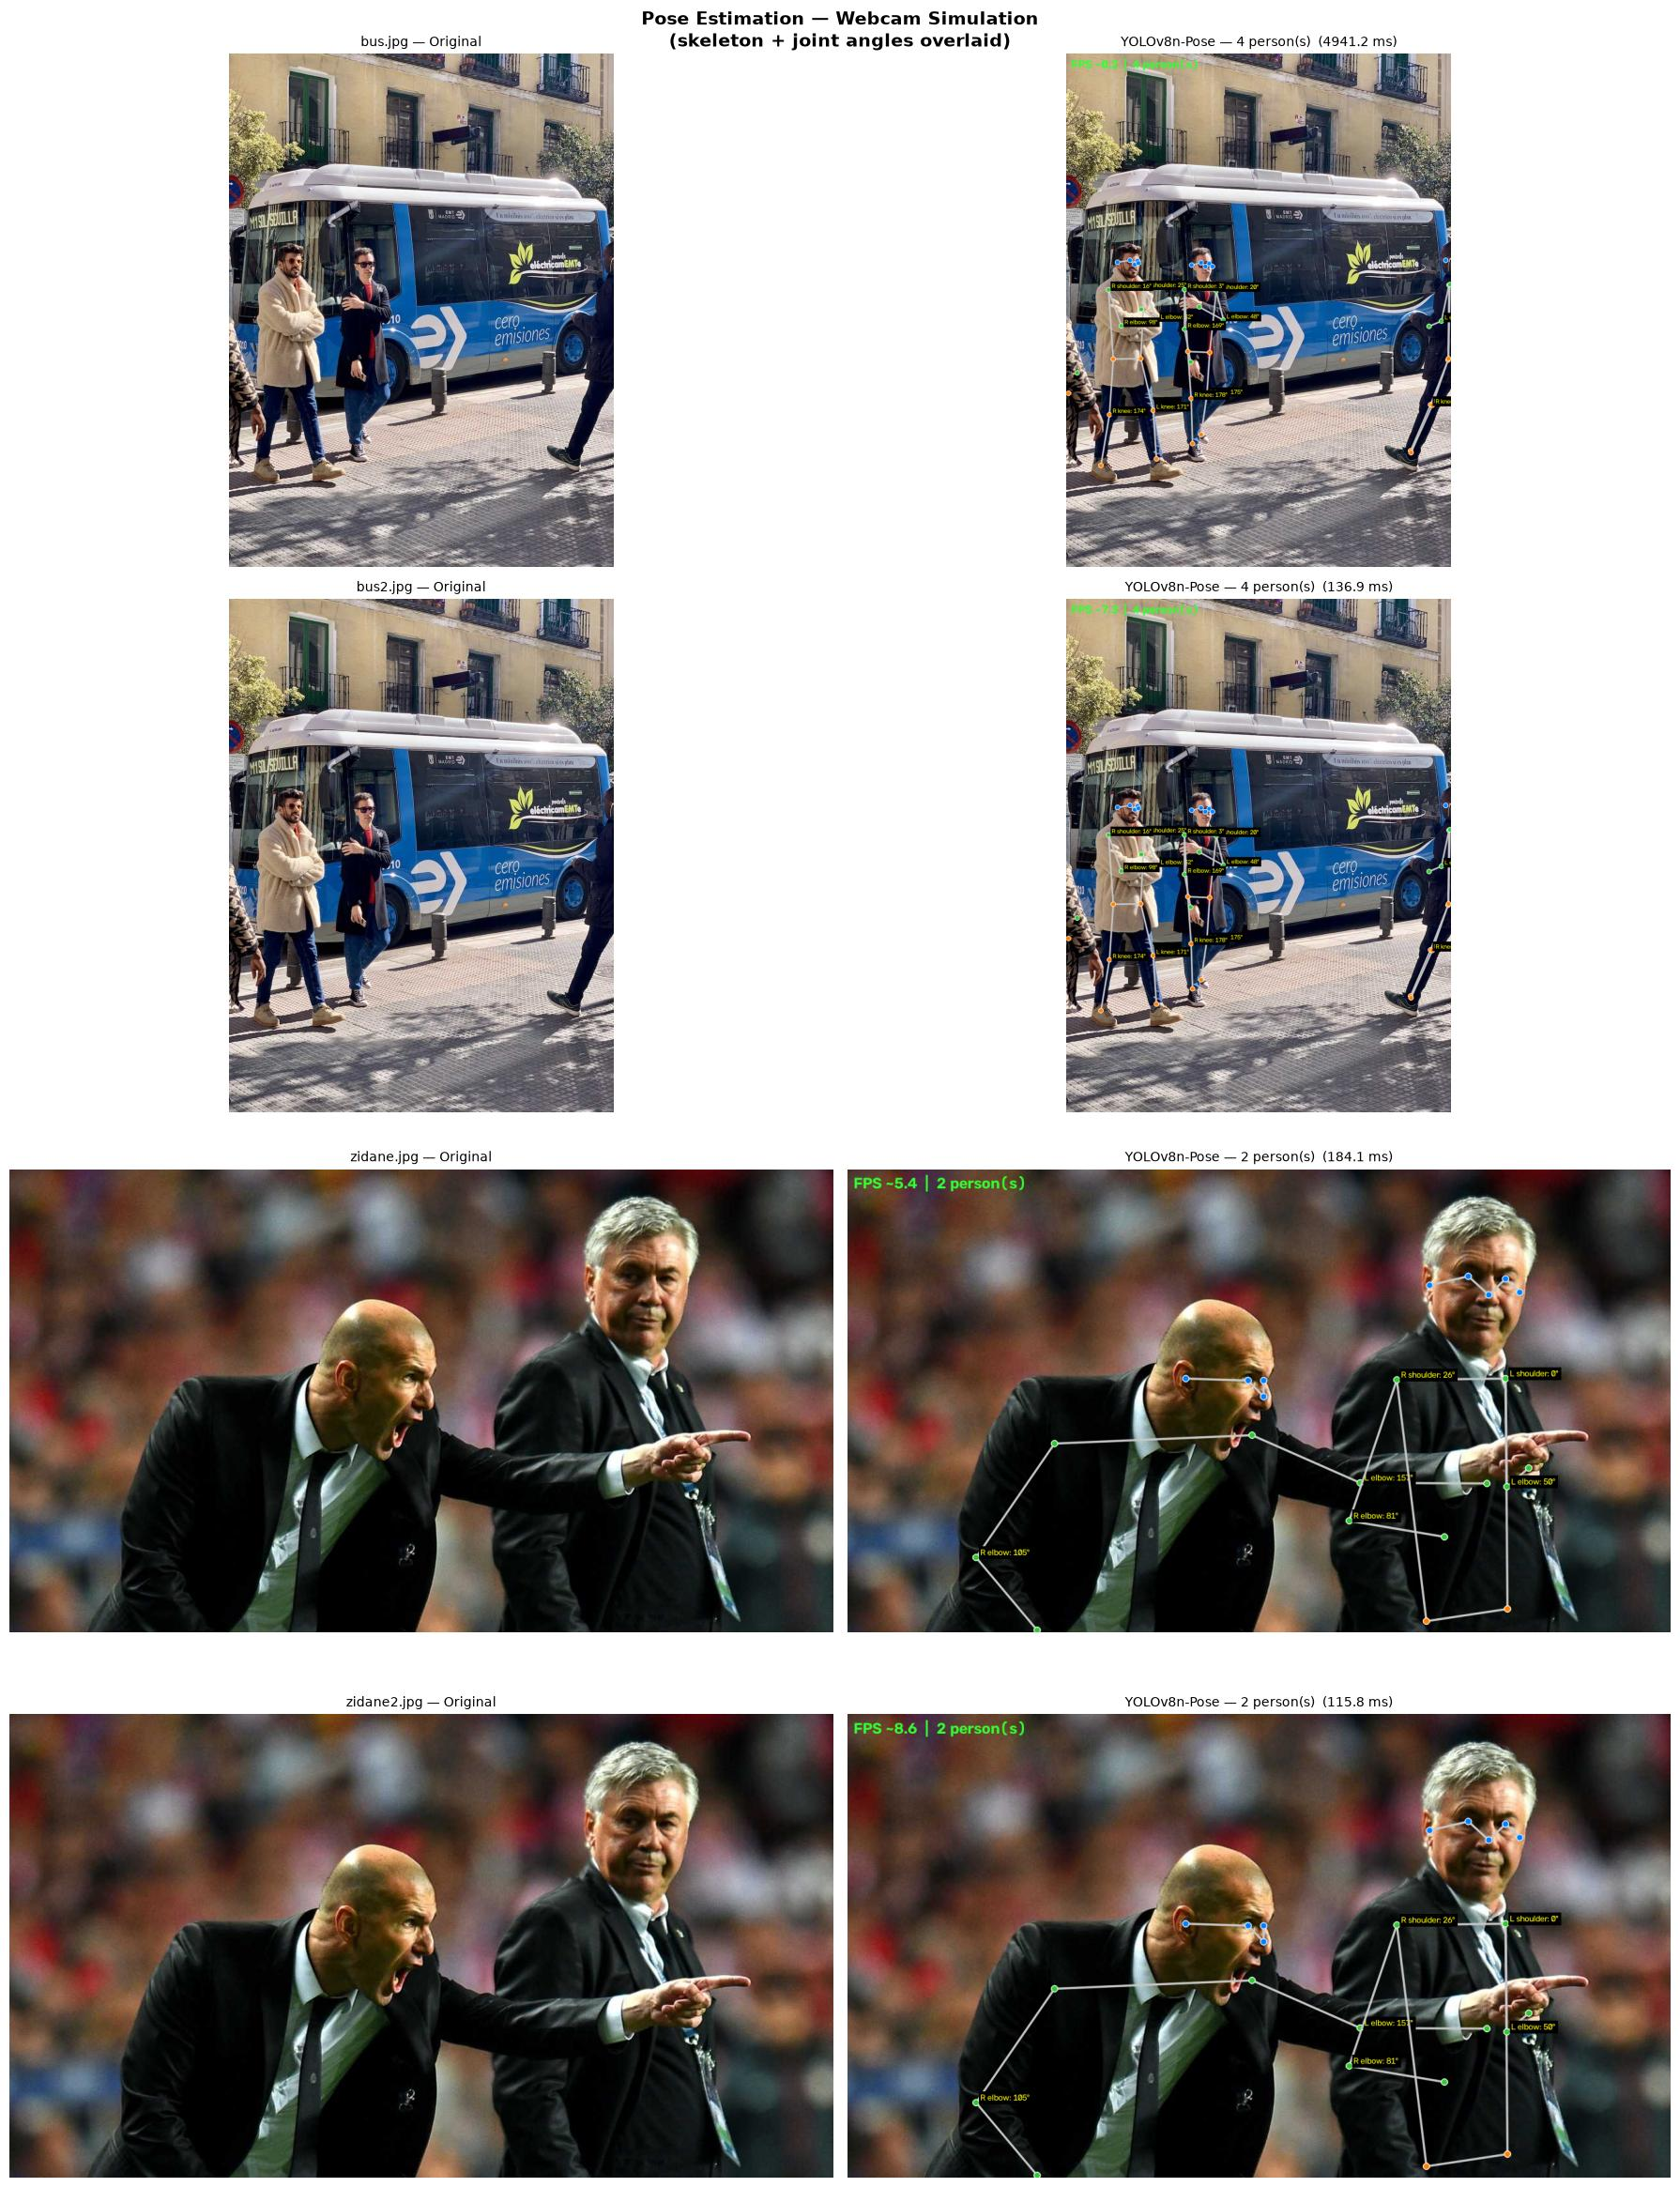

Saved → outputs_q5/q5_pose_comparison.png


In [6]:
n = len(frame_records)
fig, axes = plt.subplots(n, 2, figsize=(18, n * 6))
if n == 1: axes = [axes]

for row, r in enumerate(frame_records):
    axes[row][0].imshow(r["original"])
    axes[row][0].set_title(f"{r['name']} — Original", fontsize=10)
    axes[row][0].axis("off")

    axes[row][1].imshow(r["annotated"])
    axes[row][1].set_title(
        f"YOLOv8n-Pose — {r['n_people']} person(s)  ({r['infer_ms']:.1f} ms)",
        fontsize=10)
    axes[row][1].axis("off")

plt.suptitle("Pose Estimation — Webcam Simulation\n"
             "(skeleton + joint angles overlaid)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT / "q5_pose_comparison.png", dpi=85, bbox_inches="tight")
plt.show()
print("Saved → outputs_q5/q5_pose_comparison.png")

## 6 — Joint Angle Results

In [7]:
print(f"{'Frame':<26} {'Person':>7}  {'Angle name':<14} {'Degrees':>10}")
print("=" * 65)
for r in frame_records:
    for pid, angles in enumerate(r["all_angles"]):
        for aname, deg in angles.items():
            print(f"{r['name']:<26} {pid:>7}  {aname:<14} {deg:>10.1f}°")

Frame                       Person  Angle name        Degrees
bus.jpg                          0  L elbow              32.1°
bus.jpg                          0  R elbow              97.9°
bus.jpg                          0  L knee              170.5°
bus.jpg                          0  R knee              174.4°
bus.jpg                          0  L shoulder           25.4°
bus.jpg                          0  R shoulder           15.6°
bus.jpg                          1  L elbow             124.8°
bus.jpg                          1  L knee              178.1°
bus.jpg                          1  R knee              174.9°
bus.jpg                          1  L shoulder           11.2°
bus.jpg                          2  L elbow              47.6°
bus.jpg                          2  R elbow             169.3°
bus.jpg                          2  L knee              175.4°
bus.jpg                          2  R knee              177.8°
bus.jpg                          2  L shoulder          

## 7 — Joint Angle Bar Chart

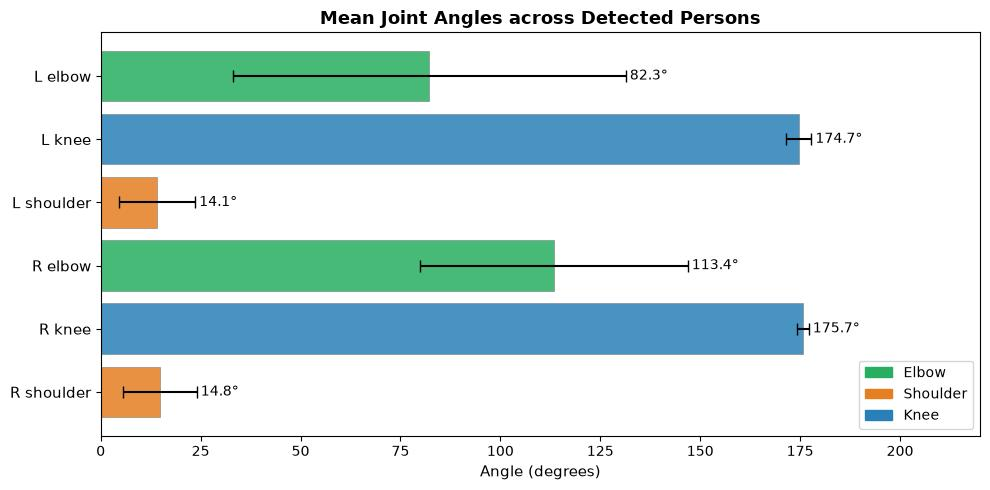

Saved → outputs_q5/q5_joint_angles.png


In [8]:
# Gather all angles across all frames and persons
from collections import defaultdict
angle_data = defaultdict(list)

for r in frame_records:
    for angles in r["all_angles"]:
        for aname, deg in angles.items():
            angle_data[aname].append(deg)

if angle_data:
    names_a = sorted(angle_data.keys())
    means_a = [np.mean(angle_data[n]) for n in names_a]
    stds_a  = [np.std(angle_data[n])  for n in names_a]

    colors_a = []
    for n in names_a:
        if "elbow"    in n: colors_a.append("#27ae60")
        elif "knee"   in n: colors_a.append("#2980b9")
        else:               colors_a.append("#e67e22")

    fig, ax = plt.subplots(figsize=(10, 5))
    y_pos = np.arange(len(names_a))
    bars  = ax.barh(y_pos, means_a, xerr=stds_a, color=colors_a,
                    edgecolor="grey", linewidth=0.5, capsize=4, alpha=0.85)

    for i, (mean, std, name) in enumerate(zip(means_a, stds_a, names_a)):
        ax.text(mean + std + 1, i, f"{mean:.1f}°", va="center", fontsize=10)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(names_a, fontsize=11)
    ax.set_xlabel("Angle (degrees)", fontsize=11)
    ax.set_title("Mean Joint Angles across Detected Persons",
                 fontsize=13, fontweight="bold")
    ax.set_xlim(0, 220)
    ax.invert_yaxis()

    # Legend
    legend_handles = [
        mpatches.Patch(color="#27ae60", label="Elbow"),
        mpatches.Patch(color="#e67e22", label="Shoulder"),
        mpatches.Patch(color="#2980b9", label="Knee"),
    ]
    ax.legend(handles=legend_handles, fontsize=10, loc="lower right")

    plt.tight_layout()
    plt.savefig(OUT / "q5_joint_angles.png", dpi=90, bbox_inches="tight")
    plt.show()
    print("Saved → outputs_q5/q5_joint_angles.png")
else:
    print("No joint angle data to plot (no visible joints detected).")

## 8 — Skeleton Diagram: Keypoint Map

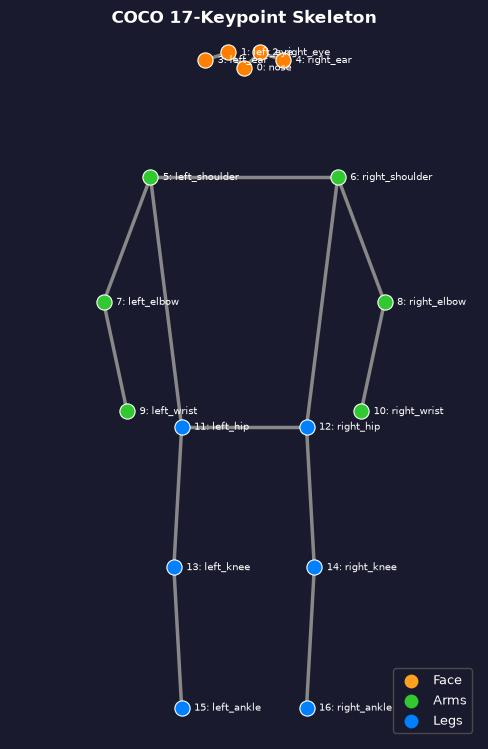

Saved → outputs_q5/q5_skeleton_diagram.png


In [9]:
# Draw an annotated diagram of the COCO 17-keypoint skeleton on a blank canvas
fig, ax = plt.subplots(figsize=(5, 9))
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-2.5, 2.0)
ax.set_aspect("equal")
ax.set_facecolor("#1a1a2e")
fig.patch.set_facecolor("#1a1a2e")
ax.axis("off")

# Canonical normalised positions (y flipped for matplotlib)
KP_POS = {
    0:  (0.0,  1.8),   # nose
    1:  (-0.1, 1.9),   # left_eye
    2:  ( 0.1, 1.9),   # right_eye
    3:  (-0.25,1.85),  # left_ear
    4:  ( 0.25,1.85),  # right_ear
    5:  (-0.6, 1.1),   # left_shoulder
    6:  ( 0.6, 1.1),   # right_shoulder
    7:  (-0.9, 0.3),   # left_elbow
    8:  ( 0.9, 0.3),   # right_elbow
    9:  (-0.75,-0.4),  # left_wrist
    10: ( 0.75,-0.4),  # right_wrist
    11: (-0.4,-0.5),   # left_hip
    12: ( 0.4,-0.5),   # right_hip
    13: (-0.45,-1.4),  # left_knee
    14: ( 0.45,-1.4),  # right_knee
    15: (-0.4,-2.3),   # left_ankle
    16: ( 0.4,-2.3),   # right_ankle
}

for a, b in SKELETON:
    xa,ya = KP_POS[a]; xb,yb = KP_POS[b]
    ax.plot([xa,xb],[ya,yb], color="#888888", linewidth=2.5, zorder=1)

for idx, (x,y) in KP_POS.items():
    col = "#{:02x}{:02x}{:02x}".format(*kp_color(idx))
    ax.scatter(x, y, s=120, c=col, zorder=3, edgecolors="white", linewidths=0.8)
    ax.text(x + 0.08, y, f"{idx}: {KP_NAMES[idx]}", fontsize=7,
            color="white", va="center", zorder=4)

ax.set_title("COCO 17-Keypoint Skeleton", fontsize=12,
             fontweight="bold", color="white", pad=10)

# Colour legend
for col, lbl in [("#ffa020","Face"), ("#32c832","Arms"), ("#0080ff","Legs")]:
    ax.scatter([], [], c=col, s=80, label=lbl)
ax.legend(fontsize=9, labelcolor="white", facecolor="#1a1a2e",
          edgecolor="#555", loc="lower right")

plt.tight_layout()
plt.savefig(OUT / "q5_skeleton_diagram.png", dpi=100, bbox_inches="tight",
            facecolor="#1a1a2e")
plt.show()
print("Saved → outputs_q5/q5_skeleton_diagram.png")

## 9 — FPS Summary

In [10]:
times_ms = [r["infer_ms"] for r in frame_records]
print("=" * 45)
print("  POSE ESTIMATION SPEED SUMMARY")
print("=" * 45)
print(f"  Frames processed : {len(times_ms)}")
print(f"  Min latency      : {min(times_ms):.1f} ms")
print(f"  Mean latency     : {np.mean(times_ms):.1f} ms")
print(f"  Max latency      : {max(times_ms):.1f} ms")
print(f"  Estimated FPS    : {1000/np.mean(times_ms):.1f}")
print()
print("  For real-time webcam use, run on GPU for 60+ FPS.")
print("  On CPU, 10–30 FPS is typical for YOLOv8n-Pose.")

  POSE ESTIMATION SPEED SUMMARY
  Frames processed : 4
  Min latency      : 115.8 ms
  Mean latency     : 1344.5 ms
  Max latency      : 4941.2 ms
  Estimated FPS    : 0.7

  For real-time webcam use, run on GPU for 60+ FPS.
  On CPU, 10–30 FPS is typical for YOLOv8n-Pose.


## Summary

| Item | Detail |
|------|--------|
| Model | YOLOv8n-Pose (6.4 MB, pre-trained COCO) |
| Keypoints | 17 per person (COCO format) |
| Input | Simulated webcam (looped JPEG images) |
| Skeleton | 17 edges connecting body joints |
| Joint angles | Elbow, Knee, Shoulder (left & right) |
| Angle method | Law of cosines between 3-point vectors |

**Joint Angle Interpretation:**
- **Elbow ≈ 180°** → arm fully extended
- **Elbow ≈ 90°** → arm bent at right angle
- **Knee ≈ 180°** → leg straight
- **Shoulder ≈ 90°** → arm raised sideways

**Real webcam usage:**
```python
# Replace SimulatedWebcam with:
cam = cv2.VideoCapture(0)
while cam.isOpened():
    ok, frame = cam.read()
    if not ok: break
    res = model(frame, verbose=False)
    # ... draw skeleton + angles ...
    cv2.imshow("Pose", annotated_frame)
    if cv2.waitKey(1) & 0xFF == ord('q'): break
cam.release()
cv2.destroyAllWindows()
```